In [91]:
# imoprt the required liraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import tensorflow
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score


import warnings
warnings.filterwarnings("ignore")


In [92]:
# load the data
df=pd.read_csv("/content/nvda_stock.csv")

In [93]:
df

,Date,Open,High,Low,Close,Volume
0,2010-01-04,0.424242,0.426763,0.415074,0.423784,800204000
1,2010-01-05,0.422179,0.434556,0.422179,0.429972,728648000
2,2010-01-06,0.429743,0.433639,0.425617,0.432722,649168000
3,2010-01-07,0.430430,0.432264,0.421033,0.424242,547792000
4,2010-01-08,0.420804,0.428139,0.418283,0.425159,478168000
...,...,...,...,...,...,...
4103,2026-04-28,209.490005,214.729996,208.199997,213.169998,180275400
4104,2026-04-29,212.699997,212.720001,207.580002,209.250000,123711800
4105,2026-04-30,209.929993,210.300003,198.699997,199.570007,225239200
4106,2026-05-01,201.279999,203.000000,197.119995,198.449997,128647000


In [94]:
# EDA

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4108 entries, 0 to 4107
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    4108 non-null   object 
 1   Open    4108 non-null   float64
 2   High    4108 non-null   float64
 3   Low     4108 non-null   float64
 4   Close   4108 non-null   float64
 5   Volume  4108 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 192.7+ KB


In [95]:
# check the summary
df.describe()

,Open,High,Low,Close,Volume
count,4108.000000,4108.000000,4108.000000,4108.000000,4.108000e+03
mean,26.024894,26.451211,25.552379,26.021081,4.735287e+08
std,49.394800,50.128682,48.547739,49.364617,3.051482e+08
min,0.199859,0.207423,0.198255,0.203526,4.564400e+07
25%,0.434635,0.440246,0.428689,0.434418,2.774374e+08
50%,4.114192,4.168928,4.059048,4.104808,4.043840e+08
75%,19.244044,19.592118,18.803971,19.263086,5.809790e+08
max,212.699997,216.830002,208.199997,216.610001,3.692928e+09


In [96]:
# drop the date column

df=df.drop("Date",axis=1)

In [97]:
# Handel the outliers
out_cols=["Open","High","Low","Volume"]

for col in out_cols:
  q1= df[col].quantile(0.25)
  q3=df[col].quantile(0.75)

  IQR=q3-q1

  ub=q3+1.5*IQR
  lb=q1-1.5*IQR

  df[col]=df[col].clip(lower=lb,upper=ub)

In [98]:
df.describe()

,Open,High,Low,Close,Volume
count,4108.000000,4108.000000,4108.000000,4108.000000,4.108000e+03
mean,12.981921,13.219679,12.707587,26.021081,4.554706e+08
std,17.274245,17.589907,16.888393,49.364617,2.330881e+08
min,0.199859,0.207423,0.198255,0.203526,4.564400e+07
25%,0.434635,0.440246,0.428689,0.434418,2.774374e+08
50%,4.114192,4.168928,4.059048,4.104808,4.043840e+08
75%,19.244044,19.592118,18.803971,19.263086,5.809790e+08
max,47.458158,48.319926,46.366894,216.610001,1.036291e+09


In [99]:
# divide the data int the x y var

X=df.drop("Close",axis=1)
y=df["Close"]

In [100]:
# scale the data]
scaler=StandardScaler()

X_scaled=scaler.fit_transform(X)

In [101]:
# split the data
X_train,X_test,y_train,y_test=train_test_split(X_scaled,y,random_state=42,test_size=0.2)

In [102]:
# model building
model=Sequential()

# first hiden layer
model.add(Dense(64,activation='relu',input_shape=(X_train.shape[1],)))

# second hiden layer
model.add(Dense(32,activation='relu'))

# ?third hiden layer
model.add(Dense(16,activation='relu'))


# outpou layer
model.add(Dense(1))

In [103]:
# model compile

model.compile(optimizer=Adam(learning_rate=0.001),loss='mean_squared_error',metrics=["r2_score"])


In [89]:
# ?train the model
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=30,verbose=True)

Epoch 1/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 2992.1150 - r2_score: -0.2337 - val_loss: 2986.2256 - val_r2_score: -0.2042
Epoch 2/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2889.1594 - r2_score: -0.1912 - val_loss: 2925.7266 - val_r2_score: -0.1798
Epoch 3/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2840.3223 - r2_score: -0.1711 - val_loss: 2882.9224 - val_r2_score: -0.1625
Epoch 4/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2801.1111 - r2_score: -0.1549 - val_loss: 2846.1438 - val_r2_score: -0.1477
Epoch 5/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2766.3320 - r2_score: -0.1406 - val_loss: 2812.3403 - val_r2_score: -0.1341
Epoch 6/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2734.3127 - r2_score: -0.1274 - val_loss: 2781.5393 - val_r2_score: -0.1216
Epoch 7/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2705.0764 - r2_score: -0.1153 - val_loss: 2753.4080 - val_r2_score: -0.1103
Epoch 8/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/

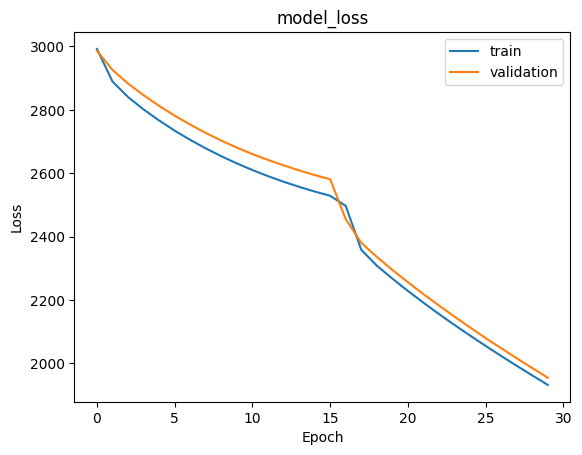

In [90]:
# check the loss plot
plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.title("model_loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(['train','validation'],loc="upper right")
plt.show()